# Exploratory Data Analysis: 500 Helpful Community Notes
What the tweets, notes and ratings look like, how they are connected, and what patterns stand out.

In [2]:
import re
from collections import Counter

import matplotlib.pyplot as plt
import pandas as pd

DATA_FOLDER = "dataset/10-05_10-13/"
SAUDI_NOTE_ID = "2109061654621098457"
MILLIS_PER_HOUR = 1000 * 60 * 60

# IDs are 19 digits long. Read as numbers they lose their last digits, so read them as text.
ID_COLUMNS = {
    "noteId": str,
    "tweetId": str,
    "noteAuthorParticipantId": str,
    "raterParticipantId": str,
    "tweet_author_id": str,
}

tweets = pd.read_csv(DATA_FOLDER + "tweets.csv", dtype=ID_COLUMNS)
notes = pd.read_csv(DATA_FOLDER + "notes.csv", dtype=ID_COLUMNS)
status = pd.read_csv(DATA_FOLDER + "note_status.csv", dtype=ID_COLUMNS)
ratings = pd.read_csv(DATA_FOLDER + "ratings.csv", dtype=ID_COLUMNS)
combined = pd.read_csv(DATA_FOLDER + "combined.csv", dtype=ID_COLUMNS)

In [3]:
BLUE = "#2a78d6"
ORANGE = "#eb6834"
GRAY = "#a3a29c"

plt.rcParams.update({
    "figure.figsize": (9, 4),
    "axes.spines.top": False,
    "axes.spines.right": False,
    "axes.grid": True,
    "grid.color": "#e6e5e0",
    "axes.axisbelow": True,
    "axes.titleweight": "bold",
    "axes.titlesize": 13,
})
pd.set_option("display.max_colwidth", 120)


def readable_name(column: str, prefix: str) -> str:
    """Turn a column name into plain words, e.g. "misleadingFactualError" -> "Factual error".

    Args:
        column: the column name.
        prefix: the start of the name to remove, e.g. "misleading".

    Returns:
        The rest of the name as lower-case words, first letter capital.
    """
    words = re.findall(r"[A-Z][a-z]*", column[len(prefix):])
    return " ".join(words).capitalize()


def percent_of_rows(table: pd.DataFrame, columns: list[str], prefix: str) -> pd.Series:
    """For 0/1 columns, the % of rows that have a 1, with readable names, smallest first."""
    shares = table[columns].mean() * 100
    shares.index = [readable_name(column, prefix) for column in columns]
    return shares.sort_values()


def plot_bar_shares(shares: pd.Series, title: str, xlabel: str):
    """Horizontal bar chart of percentages, with the value written at the end of each bar."""
    fig, ax = plt.subplots(figsize=(9, 0.45 * len(shares) + 1))
    bars = ax.barh(shares.index, shares.values, color=BLUE)
    ax.bar_label(bars, fmt="%.0f%%", padding=3)
    ax.set_title(title)
    ax.set_xlabel(xlabel)
    ax.grid(axis="y", visible=False)
    plt.show()

## 1. The dataset at a glance

The dataset has five files. They are connected by two IDs:

```
tweets ──tweetId──> notes ──noteId──> note_status
                       └──noteId──> ratings
```

One tweet has one note here, and one note has many ratings.
`combined.csv` is a convenience file: one row per note with its tweet and rating counts.

In [4]:
tables = {
    "tweets.csv": (tweets, "one tweet (from the X API)"),
    "notes.csv": (notes, "one note"),
    "note_status.csv": (status, "X's decision about one note (Helpful or not)"),
    "ratings.csv": (ratings, "one person's rating of one note"),
    "combined.csv": (combined, "one note + its tweet + rating counts"),
}

overview_rows = []
for file_name, (table, one_row_is) in tables.items():
    overview_rows.append({
        "file": file_name,
        "one row is": one_row_is,
        "rows": len(table),
        "columns": len(table.columns),
    })

pd.DataFrame(overview_rows)

,file,one row is,rows,columns
0,tweets.csv,one tweet (from the X API),500,10
1,notes.csv,one note,500,24
2,note_status.csv,X's decision about one note (Helpful or not),500,24
3,ratings.csv,one person's rating of one note,43656,35
4,combined.csv,one note + its tweet + rating counts,500,19


In [5]:
print("Tweets:      ", tweets["tweetId"].nunique())
print("Notes:       ", notes["noteId"].nunique())
print("Note writers:", notes["noteAuthorParticipantId"].nunique())
print("Ratings:     ", len(ratings))
print("Raters:      ", ratings["raterParticipantId"].nunique())

Tweets:       500
Notes:        500
Note writers: 170
Ratings:      43656
Raters:       30747


500 tweets, 500 notes (one per tweet), written by only **170 people**,
and rated **43,656 times by 30,747 different raters**. Ratings are by far the largest part of the data.

### 1.1 What is inside each file

The important columns of each file, what they mean, and a **real example**: the values for the
"SAUDI IS BURNING" note, which is in this dataset.

Times ending in `Millis` are **milliseconds since Jan 1, 1970 (UTC)**, the way X stores time.
For example, `1791674457589` = Oct 10, 2026, 23:20 UTC.

---

#### `tweets.csv`: one row per tweet (downloaded from the X API)

| Column | Meaning | Example |
|---|---|---|
| `tweetId` | ID of the tweet. Links to `notes.csv` | 2109031558967615703 |
| `tweet_text` | Text of the tweet | SAUDI IS BURNING |
| `tweet_created_at` | When the tweet was posted (UTC) | 2026-10-10 21:21 |
| `tweet_like_count`, `tweet_retweet_count`, `tweet_reply_count`, `tweet_quote_count` | Engagement, counted on the day we downloaded the tweet | 2,226 / 222 / 1,624 / 197 |
| `tweet_author_id` | ID of the account that posted the tweet | 1.3192877610487235e+18 (damaged, see Limitations) |
| `tweet_lang` | Language of the tweet | en |
| `tweet_status` | Whether the tweet still exists | ok |

---

#### `notes.csv`: one row per note (from X's Notes file)

| Column | Meaning | Example |
|---|---|---|
| `noteId` | ID of the note. Links to `note_status.csv` and `ratings.csv` | 2109061654621098457 |
| `tweetId` | The tweet the note is about | 2109031558967615703 |
| `noteAuthorParticipantId` | Anonymous ID of the note writer | 38803E65... |
| `createdAtMillis` | When the note was written | 1791674457589 (Oct 10, 23:20) |
| `classification` | The writer's verdict on the tweet: `MISINFORMED_OR_POTENTIALLY_MISLEADING` or `NOT_MISLEADING` | MISINFORMED_OR_POTENTIALLY_MISLEADING |
| `misleading...` (7 columns) | **Why** the tweet is misleading. 1 = the writer ticked this reason | MissingImportantContext = 1, UnverifiedClaimAsFact = 1 |
| `notMisleading...` (5 columns) | Why the tweet is *not* misleading (only used by `NOT_MISLEADING` notes) | all 0 |
| `trustworthySources` | The writer says the note uses trustworthy sources (1 = yes) | 1 |
| `summary` | **The text of the note** | "Saudi is burning" misleadingly implies nationwide fires... |
| `isMediaNote` | 1 = the note is about an image or video, and is shown on every post with that media | 0 |

---

#### `note_status.csv`: one row per note: **X's decision about the note**

X's algorithm regularly looks at all ratings and gives each note a **status**:
- `CURRENTLY_RATED_HELPFUL`: the note is **shown on X** under the tweet.
- `NEEDS_MORE_RATINGS` (NMR): **not decided yet**, the note is not shown.
- `CURRENTLY_RATED_NOT_HELPFUL`: decided as **not helpful**, the note is not shown.

| Column | Meaning | Example |
|---|---|---|
| `noteId` | The note | 2109061654621098457 |
| `currentStatus` | The status **now** (at download time) | CURRENTLY_RATED_HELPFUL |
| `firstNonNMRStatus` | The **first** real decision (the first status that was not "Needs More Ratings") | CURRENTLY_RATED_HELPFUL |
| `timestampMillisOfFirstNonNMRStatus` | **When** that first decision was made. We use it for "hours to become Helpful" | 1791694251343 (Oct 11, 04:50) |
| `currentDecidedBy` | **Which model** of the algorithm made the decision | ExpansionModel (v1.1) |
| `currentCoreStatus`, `currentExpansionStatus`, `currentGroupStatus` | Each model's own verdict. Empty = that model gave no result | empty / CURRENTLY_RATED_HELPFUL / empty |
| `lockedStatus` | After about two weeks, X freezes ("locks") a note's status | empty (not locked yet) |
| other `timestampMillis...` columns | Times of special events. Mostly empty | |

---

#### `ratings.csv`: one row per rating (one person rating one note)

| Column | Meaning | Example (the first rating the Saudi note received) |
|---|---|---|
| `noteId` | The note that was rated | 2109061654621098457 |
| `raterParticipantId` | Anonymous ID of the rater | 27820444... |
| `createdAtMillis` | When the rating was given | 1791674679761 (Oct 10, 23:24) |
| `helpfulnessLevel` | **The rating**: `HELPFUL`, `SOMEWHAT_HELPFUL` or `NOT_HELPFUL` | NOT_HELPFUL |
| `helpful...` (9 columns) | **Why** the rater found the note helpful. 1 = ticked | all 0 |
| `notHelpful...` (13 columns) | **Why** the rater found the note not helpful. 1 = ticked | ArgumentativeOrBiased = 1 |
| `ratedOnTweetId` | The tweet on which the rater saw the note | 2109031558967615703 |
| `ratingSourceBucketed` | How the rater got the note: `DEFAULT` (normal) or `POPULATION_SAMPLED` (X picked the rater as part of a sample) | DEFAULT |
| `version`, `agree`, `disagree`, `helpful`, `notHelpful` | Old rating format, always 0 here | |

---

#### `combined.csv`: one row per note (**made by us** for easy reading)

It joins the other four files. Besides the tweet columns above, it has:

| Column | Meaning | Example |
|---|---|---|
| `note_text` | Same as `summary` in `notes.csv` | "Saudi is burning" misleadingly implies... |
| `classification1` | The **writer's** label on the tweet (`classification` in `notes.csv`) | MISINFORMED_OR_POTENTIALLY_MISLEADING |
| `classification2` | The **algorithm's** label on the note (`currentStatus` in `note_status.csv`) | CURRENTLY_RATED_HELPFUL |
| `note_created_at` | When the note was written, as a readable date | 2026-10-10 23:20:57 UTC |
| `ratings_helpful`, `ratings_somewhat`, `ratings_not_helpful`, `ratings_total` | Rating counts, counted from `ratings.csv` | 135 / 3 / 27 / 165 |

Every note has **two labels**: the writer says whether the *tweet* is misleading (`classification1`),
and the algorithm, based on ratings, says whether the *note* is helpful (`classification2`).

## 2. The tweets

How popular are the tweets that received a Helpful note?

In [7]:
engagement_columns = ["tweet_like_count", "tweet_retweet_count", "tweet_reply_count", "tweet_quote_count"]

engagement_rows = []
for column in engagement_columns:
    values = tweets[column]
    engagement_rows.append({
        "measure": column,
        "min": values.min(),
        "median": values.median(),
        "mean": round(values.mean()),
        "max": values.max(),
    })

pd.DataFrame(engagement_rows)

,measure,min,median,mean,max
0,tweet_like_count,6.0,3564.5,10325,137769.0
1,tweet_retweet_count,0.0,236.5,953,12590.0
2,tweet_reply_count,0.0,240.5,675,34815.0
3,tweet_quote_count,0.0,82.0,200,6619.0


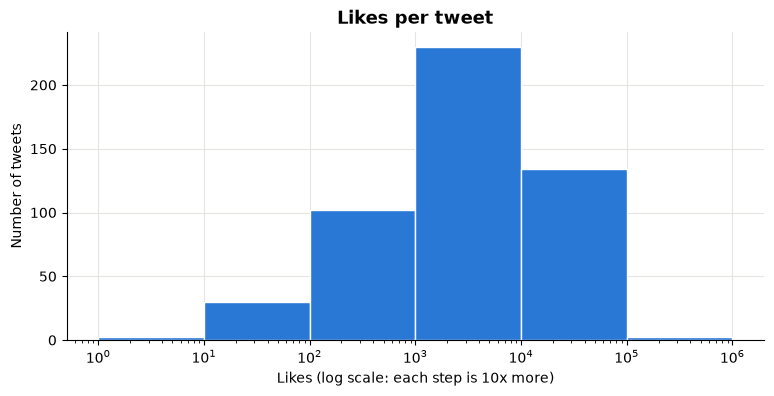

In [8]:
fig, ax = plt.subplots()
like_bins = [10 ** power for power in range(0, 7)]
ax.hist(tweets["tweet_like_count"], bins=like_bins, color=BLUE, edgecolor="white")
ax.set_xscale("log")
ax.set_title("Likes per tweet")
ax.set_xlabel("Likes (log scale: each step is 10x more)")
ax.set_ylabel("Number of tweets")
plt.show()

The tweets are mostly **popular tweets**: the median tweet has about **3,600 likes**.
The average (about 10,300) is much higher than the median because a few tweets went viral
(up to 137,769 likes). With data this skewed, the **median** is the better "typical" value,
and a log scale is needed to see the shape.

"Helpful notes are mostly on popular tweets."

### 2.1 How old was the tweet when the note was written?

In [11]:

note_times = notes[["noteId", "tweetId", "createdAtMillis"]].merge(
    tweets[["tweetId", "tweet_created_at"]], on="tweetId"
)
note_times["note_written"] = pd.to_datetime(note_times["createdAtMillis"], unit="ms", utc=True)
note_times["tweet_posted"] = pd.to_datetime(note_times["tweet_created_at"], utc=True)
note_times["hours_tweet_to_note"] = (
    note_times["note_written"] - note_times["tweet_posted"]
).dt.total_seconds() / 3600

hours = note_times["hours_tweet_to_note"]
print(f"Median time from tweet to note: {hours.median():.1f} hours")
print(f"Notes written within 6 hours:   {(hours <= 6).mean() * 100:.0f}%")
print(f"Notes written within 24 hours:  {(hours <= 24).mean() * 100:.0f}%")
print(f"Notes on tweets older than 7 days: {(hours > 24 * 7).sum()}")

Median time from tweet to note: 6.6 hours
Notes written within 6 hours:   46%
Notes written within 24 hours:  92%
Notes on tweets older than 7 days: 7


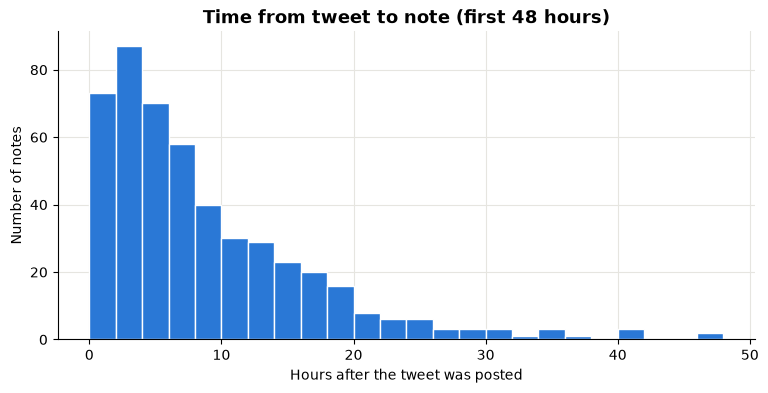

In [12]:
fig, ax = plt.subplots()
hour_bins = list(range(0, 49, 2))
first_two_days = hours[hours <= 48]
ax.hist(first_two_days, bins=hour_bins, color=BLUE, edgecolor="white")
ax.set_title("Time from tweet to note (first 48 hours)")
ax.set_xlabel("Hours after the tweet was posted")
ax.set_ylabel("Number of notes")
plt.show()

 notes are written **fast**: the median note comes **6.6 hours** after the tweet,
and **92%** come within 24 hours. Only 7 notes were written on tweets older than a week
(some from previous years, probably shared again).

## 3. The notes

### 3.1 Why did the writer say the tweet is misleading?
When writing a note, the writer ticks one or more reasons.

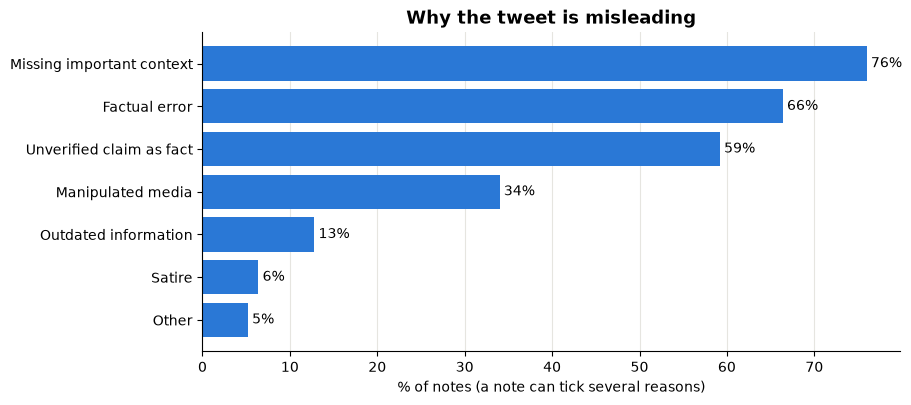

In [13]:
misleading_columns = [column for column in notes.columns if column.startswith("misleading")]
misleading_shares = percent_of_rows(notes, misleading_columns, "misleading")
plot_bar_shares(misleading_shares, "Why the tweet is misleading", "% of notes (a note can tick several reasons)")

In [14]:
reasons_per_note = notes[misleading_columns].sum(axis=1)
notes_by_reason_count = reasons_per_note.value_counts().sort_index()

pd.DataFrame({"reasons ticked": notes_by_reason_count.index, "notes": notes_by_reason_count.values})

,reasons ticked,notes
0,0,20
1,1,117
2,2,84
3,3,143
4,4,96
5,5,38
6,6,2


The most common problem is **missing important context** (76% of notes),
then **factual error** (66%) and **unverified claim presented as fact** (59%).
Manipulated media (photos/videos) appears in about a third of notes. Satire is rare.
Most notes tick **1 to 4 reasons** (3 is the most common), so a misleading tweet usually has more than one problem.
20 notes ticked no reason at all.

### 3.2 Sources and note length

In [15]:
note_text = notes["summary"]
has_link = note_text.str.contains("http")
note_length = note_text.str.len()

print(f"Writer says sources are trustworthy: {notes['trustworthySources'].mean() * 100:.0f}%")
print(f"Note contains at least one link:     {has_link.mean() * 100:.1f}%")
print(f"Media notes (about an image/video):  {notes['isMediaNote'].mean() * 100:.1f}%")
print(f"Collaborative notes:                 {notes['isCollaborativeNote'].mean() * 100:.1f}%")
print()
print(f"Note length, median: {note_length.median():.0f} characters")

Writer says sources are trustworthy: 96%
Note contains at least one link:     99.4%
Media notes (about an image/video):  4.2%
Collaborative notes:                 4.0%

Note length, median: 378 characters


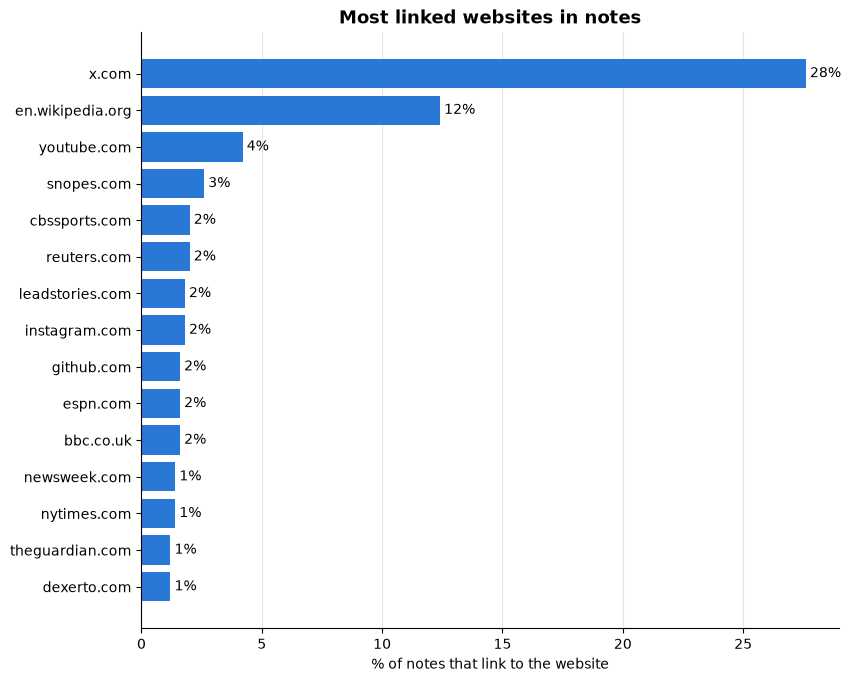

In [16]:
def link_websites(text: str) -> set[str]:
    """Return the websites linked in a note, e.g. {"reuters.com", "x.com"}."""
    websites = set()
    for link in re.findall(r"https?://\S+", text):
        website = link.split("/")[2].lower()
        website = website.removeprefix("www.")
        websites.add(website)
    return websites


website_counts = Counter()
for text in note_text:
    website_counts.update(link_websites(text))

top_websites = pd.Series(dict(website_counts.most_common(15)))
top_website_shares = (top_websites / len(notes) * 100).sort_values()
plot_bar_shares(top_website_shares, "Most linked websites in notes", "% of notes that link to the website")

Almost every Helpful note (**99%**) includes a link, so **sources matter**.
The most linked website is **x.com** itself (28% of notes; notes often point to another post,
e.g. an official account or the original video), then **Wikipedia** (12%) and YouTube (4%).
Fact-checking sites (Snopes, Lead Stories) and news sites (Reuters, BBC) follow. Sports and gaming
sites (CBS Sports, ESPN, Dexerto) show that misinformation is not only about politics.
A typical note is about **380 characters** long.

## 4. The note writers

Who writes these notes? Are they spread across many people or concentrated in a few?
And are they **people or AI**? Since 2025, X lets developers connect **AI note writers** through an API.
X's User Enrollment file marks these accounts with the status `apiEarnedIn`.

In [17]:
# The dataset folder has no user file, so read X's full User Enrollment file (only the 2 columns we need)
enrollment = pd.read_csv(
    "data/userEnrollment-00000.tsv",
    sep="\t",
    usecols=["participantId", "enrollmentState"],
    dtype={"participantId": str},
)
writer_status = enrollment.set_index("participantId")["enrollmentState"]

notes["writer status"] = notes["noteAuthorParticipantId"].map(writer_status)
notes["writer type"] = "Human"
is_ai_writer = notes["writer status"] == "apiEarnedIn"
notes.loc[is_ai_writer, "writer type"] = "AI"

writer_summary = notes.groupby("writer type").agg(
    notes=("noteId", "count"),
    writers=("noteAuthorParticipantId", "nunique"),
)
writer_summary["% of notes"] = (writer_summary["notes"] / len(notes) * 100).round(0)
writer_summary

,notes,writers,% of notes
writer type,,,
AI,314,15,63.0
Human,186,155,37.0


In [18]:
print("AI writer accounts in ALL of X's data:", (enrollment["enrollmentState"] == "apiEarnedIn").sum())

AI writer accounts in ALL of X's data: 39


In [19]:
notes_per_writer = notes["noteAuthorParticipantId"].value_counts()

total_writers = len(notes_per_writer)
writers_with_one_note = (notes_per_writer == 1).sum()
top_5_share = notes_per_writer.head(5).sum() / len(notes) * 100
top_10_share = notes_per_writer.head(10).sum() / len(notes) * 100

print("Writers:                     ", total_writers)
print("Writers with only one note:  ", writers_with_one_note)
print(f"Notes written by the top 5:   {top_5_share:.0f}%")
print(f"Notes written by the top 10:  {top_10_share:.0f}%")

Writers:                      170
Writers with only one note:   148
Notes written by the top 5:   51%
Notes written by the top 10:  65%


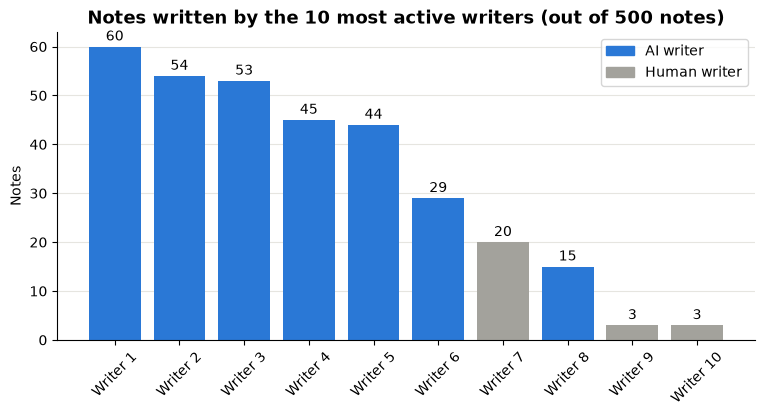

In [16]:
top_writers = notes_per_writer.head(10)
writer_labels = [f"Writer {rank}" for rank in range(1, 11)]

bar_colors = []
for writer in top_writers.index:
    if writer_status.get(writer) == "apiEarnedIn":
        bar_colors.append(BLUE)
    else:
        bar_colors.append(GRAY)

fig, ax = plt.subplots()
bars = ax.bar(writer_labels, top_writers.values, color=bar_colors)
ax.bar_label(bars, padding=2)
ax.set_title("Notes written by the 10 most active writers (out of 500 notes)")
ax.set_ylabel("Notes")
ax.grid(axis="x", visible=False)
ax.legend(handles=[
    plt.Rectangle((0, 0), 1, 1, color=BLUE, label="AI writer"),
    plt.Rectangle((0, 0), 1, 1, color=GRAY, label="Human writer"),
])
plt.xticks(rotation=45)
plt.show()

This is the most important finding of the dataset:
- **63% of the Helpful notes (314 of 500) were written by AI note writers**, from just **15 AI accounts**.
  (X's whole data has only 39 such accounts.)
- Writing is **very concentrated**: the 5 most active writers wrote **51%** of all notes, and **all 5 are AI**.
- The 155 human writers mostly wrote one note each (148 of the 170 writers wrote only one).

For misinformation research this matters a lot: many patterns in "the notes" are really patterns of a few
AI systems. Notes should be analysed **separately for AI and human writers**.

## 5. The ratings

Each rating says whether a note is **Helpful**, **Somewhat Helpful** or **Not Helpful**,
and the rater can tick reasons.

In [21]:
level_counts = ratings["helpfulnessLevel"].value_counts()
level_order = ["HELPFUL", "SOMEWHAT_HELPFUL", "NOT_HELPFUL"]
level_counts = level_counts[level_order]
level_shares = level_counts / len(ratings) * 100

pd.DataFrame({"ratings": level_counts, "%": level_shares.round(1)})

,ratings,%
helpfulnessLevel,,
HELPFUL,39243,89.9
SOMEWHAT_HELPFUL,654,1.5
NOT_HELPFUL,3759,8.6


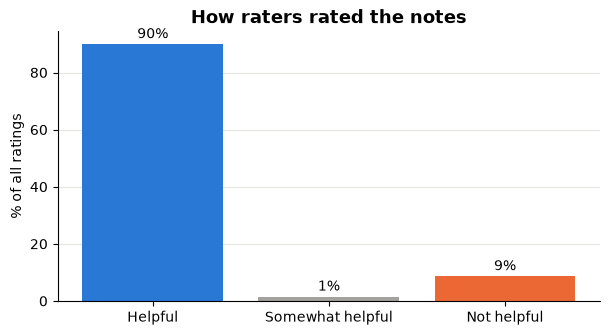

In [22]:
fig, ax = plt.subplots(figsize=(7, 3.5))
bars = ax.bar(["Helpful", "Somewhat helpful", "Not helpful"], level_shares.values, color=[BLUE, GRAY, ORANGE])
ax.bar_label(bars, fmt="%.0f%%", padding=2)
ax.set_title("How raters rated the notes")
ax.set_ylabel("% of all ratings")
ax.grid(axis="x", visible=False)
plt.show()

**90% of ratings are Helpful**. This is expected because we chose Helpful notes,
but it also shows that even Helpful notes get **some disagreement** (about 9% Not Helpful).

### 5.1 How many ratings does a note get?

In [23]:
ratings_per_note = ratings.groupby("noteId").size()
print(ratings_per_note.describe().round(0))

count     500.0
mean       87.0
std       153.0
min        14.0
25%        32.0
50%        51.0
75%        86.0
max      2377.0
dtype: float64


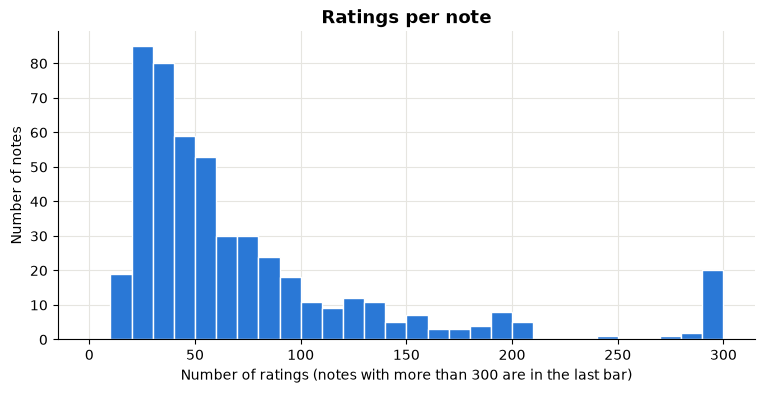

In [24]:
fig, ax = plt.subplots()
rating_bins = list(range(0, 310, 10))
ax.hist(ratings_per_note.clip(upper=300), bins=rating_bins, color=BLUE, edgecolor="white")
ax.set_title("Ratings per note")
ax.set_xlabel("Number of ratings (notes with more than 300 are in the last bar)")
ax.set_ylabel("Number of notes")
plt.show()

A typical note has about **51 ratings** (median), but a few notes get far more
(up to **2,377**). Every note has at least 14 ratings, which shows a note needs a fair number of
ratings before it can become Helpful.

### 5.2 The raters

In [25]:
ratings_per_rater = ratings["raterParticipantId"].value_counts()
print("Raters:", len(ratings_per_rater))
print(f"Raters who rated only 1 of these notes: {(ratings_per_rater == 1).mean() * 100:.0f}%")
print("Most ratings by one rater:", ratings_per_rater.max())

Raters: 30747
Raters who rated only 1 of these notes: 78%
Most ratings by one rater: 110


Ratings are **spread across many people**: about 30,700 raters, and most of them
rated only one of our 500 notes. This is the opposite of the note writers (Section 4):
few people write, many people rate.

### 5.3 Why raters found a note Helpful or Not Helpful

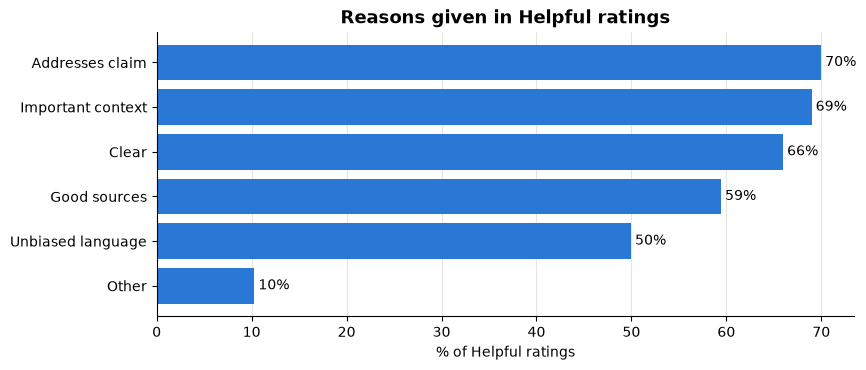

In [26]:
helpful_reason_columns = []
for column in ratings.columns:
    is_reason = column.startswith("helpful") and column not in ("helpful", "helpfulnessLevel")
    # Skip reasons X no longer offers (always 0)
    if is_reason and ratings[column].sum() > 0:
        helpful_reason_columns.append(column)

rated_helpful = ratings[ratings["helpfulnessLevel"] == "HELPFUL"]
helpful_reason_shares = percent_of_rows(rated_helpful, helpful_reason_columns, "helpful")
plot_bar_shares(helpful_reason_shares, "Reasons given in Helpful ratings", "% of Helpful ratings")

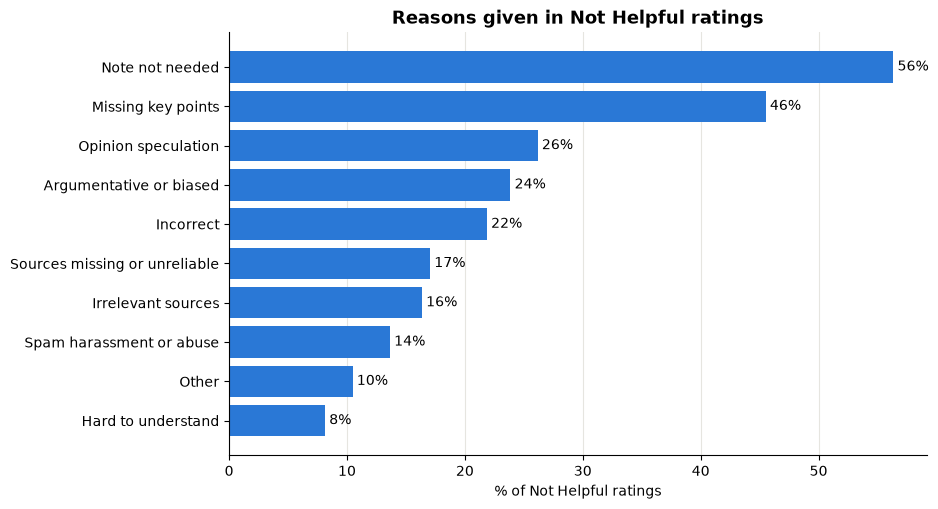

In [27]:
not_helpful_reason_columns = []
for column in ratings.columns:
    is_reason = column.startswith("notHelpful") and column != "notHelpful"
    if is_reason and ratings[column].sum() > 0:
        not_helpful_reason_columns.append(column)

rated_not_helpful = ratings[ratings["helpfulnessLevel"] == "NOT_HELPFUL"]
not_helpful_reason_shares = percent_of_rows(rated_not_helpful, not_helpful_reason_columns, "notHelpful")
plot_bar_shares(not_helpful_reason_shares, "Reasons given in Not Helpful ratings", "% of Not Helpful ratings")

- Helpful ratings mostly praise that the note **addresses the claim**, gives **important context**,
  is **clear**, and has **good sources**.
- The top Not Helpful reason is **"note not needed"**: the rater did not think the tweet was misleading
  at all.

### 5.4 How much do raters agree on each note?

In [28]:
is_helpful = ratings["helpfulnessLevel"] == "HELPFUL"
helpful_share_per_note = is_helpful.groupby(ratings["noteId"]).mean() * 100

print(helpful_share_per_note.describe().round(1))

count    500.0
mean      89.9
std        9.0
min       56.1
25%       85.7
50%       92.7
75%       96.2
max      100.0
Name: helpfulnessLevel, dtype: float64


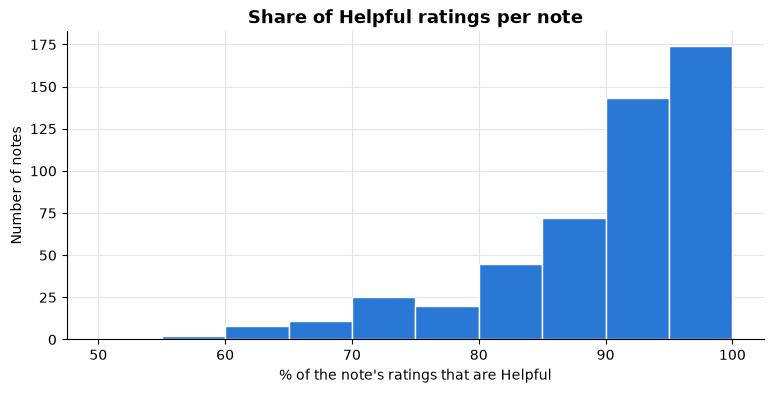

In [29]:
fig, ax = plt.subplots()
share_bins = list(range(50, 105, 5))
ax.hist(helpful_share_per_note, bins=share_bins, color=BLUE, edgecolor="white")
ax.set_title("Share of Helpful ratings per note")
ax.set_xlabel("% of the note's ratings that are Helpful")
ax.set_ylabel("Number of notes")
plt.show()

For most notes, more than 85% of raters said Helpful. But some notes became
Helpful with only **56%** Helpful ratings. So the status is **not a simple majority vote**:
X's algorithm looks for agreement among raters who **usually disagree** with each other
(the "bridging" idea).

## 6. Time

### 6.1 Notes per day

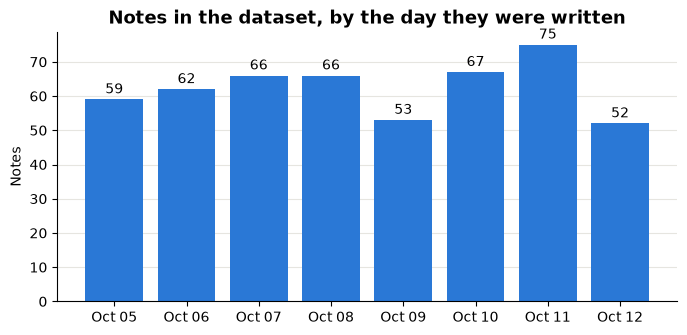

In [30]:
note_day = pd.to_datetime(notes["createdAtMillis"], unit="ms", utc=True).dt.strftime("%b %d")
notes_per_day = note_day.value_counts().sort_index()

fig, ax = plt.subplots(figsize=(8, 3.5))
bars = ax.bar(notes_per_day.index, notes_per_day.values, color=BLUE)
ax.bar_label(bars, padding=2)
ax.set_title("Notes in the dataset, by the day they were written")
ax.set_ylabel("Notes")
ax.grid(axis="x", visible=False)
plt.show()

The 500 notes are spread **evenly** over the 8 days (about 52–75 per day),

### 6.2 How long until a note becomes Helpful?

In [31]:
status["hours_to_helpful"] = (
    status["timestampMillisOfFirstNonNMRStatus"] - status["createdAtMillis"]
) / MILLIS_PER_HOUR

print("First decided status:", status["firstNonNMRStatus"].value_counts().to_dict())
print()
print(status["hours_to_helpful"].describe().round(1))

First decided status: {'CURRENTLY_RATED_HELPFUL': 500}

count    500.0
mean      12.9
std       16.5
min        1.1
25%        4.1
50%        7.9
75%       14.9
max      156.2
Name: hours_to_helpful, dtype: float64


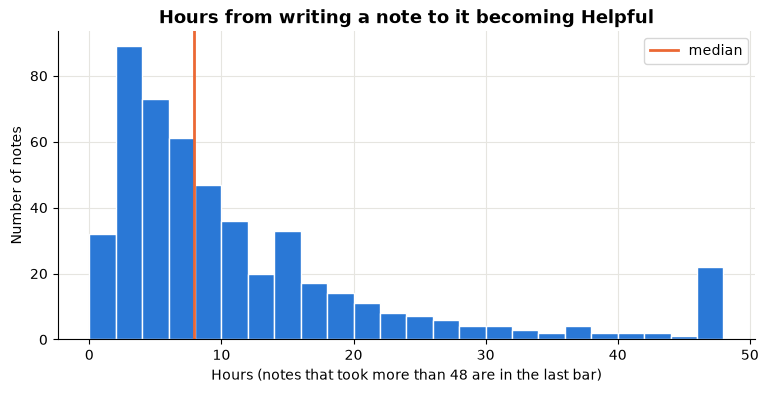

In [32]:
fig, ax = plt.subplots()
hour_bins = list(range(0, 50, 2))
ax.hist(status["hours_to_helpful"].clip(upper=48), bins=hour_bins, color=BLUE, edgecolor="white")
ax.axvline(status["hours_to_helpful"].median(), color=ORANGE, linewidth=2, label="median")
ax.set_title("Hours from writing a note to it becoming Helpful")
ax.set_xlabel("Hours (notes that took more than 48 are in the last bar)")
ax.set_ylabel("Number of notes")
ax.legend()
plt.show()

Note becomes Helpful in about **8 hours** (median). The fastest took about 1 hour,
and a few took several days. Since most tweets get most of their views in the first hours,
this delay is important: a misleading tweet may be widely seen **before** its note appears.

### 6.3 When do ratings arrive?

In [33]:
note_written = notes.set_index("noteId")["createdAtMillis"]
ratings["hours_after_note"] = (
    ratings["createdAtMillis"] - ratings["noteId"].map(note_written)
) / MILLIS_PER_HOUR

hours_after_note = ratings["hours_after_note"]
for limit in [6, 12, 24, 48]:
    share = (hours_after_note <= limit).mean() * 100
    print(f"Ratings given within {limit:>2} hours of the note: {share:.0f}%")

Ratings given within  6 hours of the note: 48%
Ratings given within 12 hours of the note: 69%
Ratings given within 24 hours of the note: 90%
Ratings given within 48 hours of the note: 98%


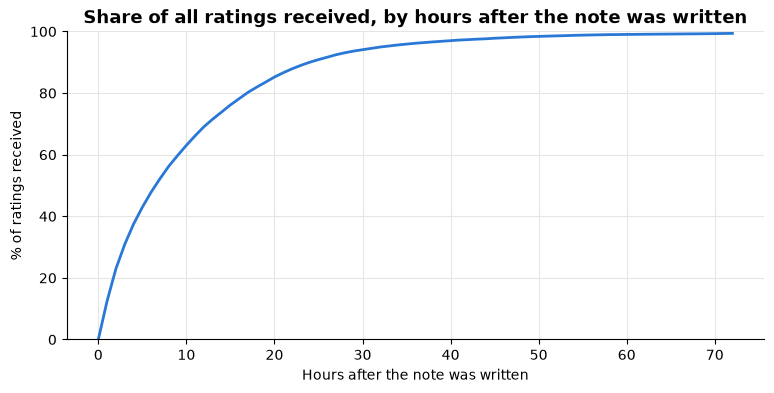

In [34]:
hour_marks = list(range(0, 73))
share_by_hour = []
for hour in hour_marks:
    share_by_hour.append((hours_after_note <= hour).mean() * 100)

fig, ax = plt.subplots()
ax.plot(hour_marks, share_by_hour, color=BLUE, linewidth=2)
ax.set_title("Share of all ratings received, by hours after the note was written")
ax.set_xlabel("Hours after the note was written")
ax.set_ylabel("% of ratings received")
ax.set_ylim(0, 100)
plt.show()

Ratings come in **quickly and then stop**: **90%** of ratings arrive within
24 hours of the note, and 98% within 48 hours. After a note is shown, rating activity drops.

popular tweets do **not** get more ratings on their note.
How many ratings a note gets seems to depend on other things
(e.g. how X shows the note to raters), not on how popular the tweet is.

### 7. Are AI-written notes different from human-written notes?

In [37]:
per_note = combined[["noteId", "ratings_total", "tweet_like_count"]].copy()
per_note = per_note.merge(notes[["noteId", "writer type"]], on="noteId")
per_note = per_note.merge(status[["noteId", "hours_to_helpful"]], on="noteId")
per_note = per_note.merge(note_times[["noteId", "hours_tweet_to_note"]], on="noteId")
per_note["helpful_share"] = per_note["noteId"].map(helpful_share_per_note)
per_note["note_length"] = per_note["noteId"].map(notes.set_index("noteId")["summary"].str.len())

comparison = per_note.groupby("writer type").agg(
    notes=("noteId", "count"),
    median_hours_tweet_to_note=("hours_tweet_to_note", "median"),
    median_hours_to_helpful=("hours_to_helpful", "median"),
    median_ratings=("ratings_total", "median"),
    median_helpful_share=("helpful_share", "median"),
    median_note_length=("note_length", "median"),
    median_tweet_likes=("tweet_like_count", "median"),
)
# Flip the table (.T) so each measure is a row: easier to read with only two groups
comparison.round(1).T

writer type,AI,Human
notes,314.0,186.0
median_hours_tweet_to_note,5.0,10.6
median_hours_to_helpful,8.0,7.5
median_ratings,43.0,61.0
median_helpful_share,93.1,92.5
median_note_length,435.0,246.5
median_tweet_likes,4633.0,2748.0


Once Helpful, AI and human notes are rated **about the same** :
- AI notes are written **twice as fast** (median 5.0 vs 10.6 hours after the tweet).
- AI notes are **longer** (435 vs 247 characters).
- AI writers pick **more popular tweets** (median 4,633 vs 2,748 likes).
- AI notes get **fewer ratings** (43 vs 61) before and after becoming Helpful.